In [ ]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt

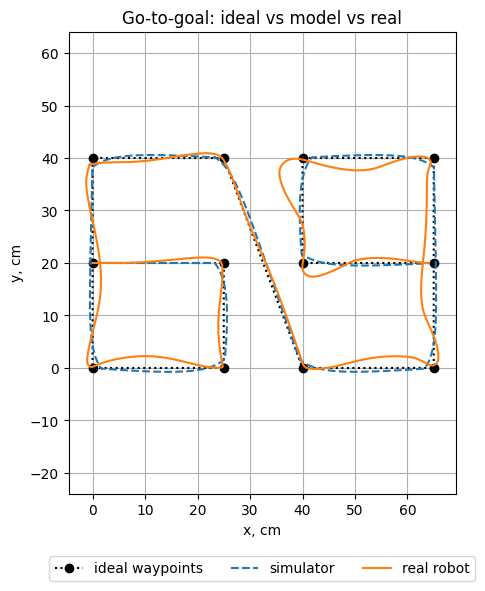

In [ ]:
wp = np.array([[0, 20], [25, 20], [25, 0], [0, 0], [0, 40], [25, 40],
               [40, 0], [65, 0], [65, 40], [40, 40], [40, 20], [65, 20]])

# reconstructing x, y, course from the wheel angles
def odometry(file, r, B):
    th_left, th_right, t = np.loadtxt(file, delimiter=',', unpack=True) #data from txt files

    path = (th_right + th_left) * r / 2
    course = (th_right - th_left) * r / B

    d_path = np.diff(path, prepend=path[0]) #how far robot moved since previous sample

    x = wp[0, 0] + np.cumsum(d_path * np.cos(course))
    y = wp[0, 1] + np.cumsum(d_path * np.sin(course))

    return x, y, course, (t - t[0]) / 1000 #start at 0 convert ms to s

x_sim, y_sim, c_sim, t_sim = odometry('/content/odometry_data_sim.txt',  2.8, 15.4)
x_real, y_real, c_real, t_real = odometry('/content/240069odometry_data_real.txt', 4.3, 19.8)

# ideal vs simulated vs real paths
plt.figure(figsize=(5,6))

plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='ideal waypoints')
plt.plot(x_sim, y_sim, '--', label='simulator')
plt.plot(x_real, y_real, label='real robot')

plt.axis('equal')
plt.grid(True)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)

plt.xlabel('x, cm')
plt.ylabel('y, cm')

plt.title('Go-to-goal: ideal vs model vs real')

plt.show()

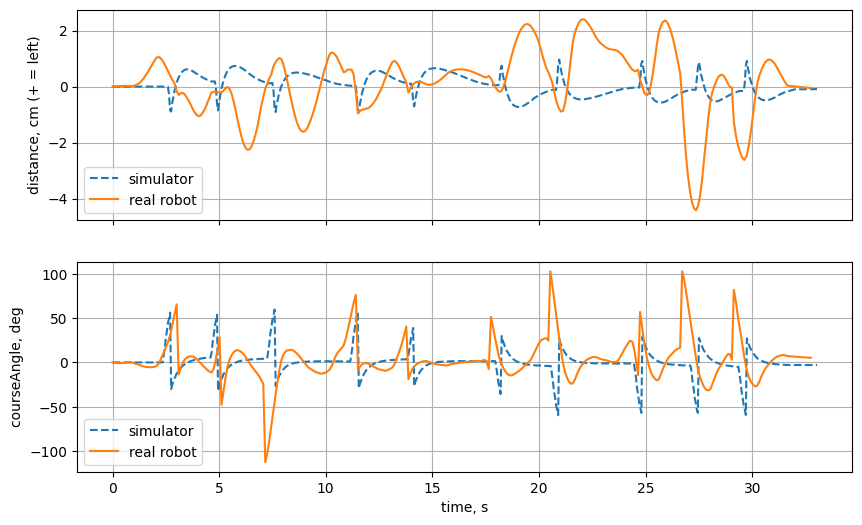

In [ ]:
# ideal segment, distance and courseAngle for every sample
def seg_dist(x, y, i):                       # distance from waypoint to where robot is
    a, b = wp[i - 1], wp[i]
    s = np.clip(np.dot([x - a[0], y - a[1]], b - a) / np.dot(b - a, b - a), 0, 1)
    return np.hypot(x - a[0] - s * (b - a)[0], y - a[1] - s * (b - a)[1])

def errors(x, y, course):
    i, dist, ang, straight = 1, [], [], []
    for xk, yk, ck in zip(x, y, course):
        if i < len(wp) - 1 and seg_dist(xk, yk, i + 1) < seg_dist(xk, yk, i):
            i += 1                           # only the current or the next segment
        (x0, y0), (x1, y1) = wp[i - 1], wp[i]

        cr = np.arctan2(y1 - y0, x1 - x0)    # course_ref[i]

        dist.append(-(xk - x0) * np.sin(cr) + (yk - y0) * np.cos(cr))

        ang.append((np.degrees(cr - ck) + 180) % 360 - 180)

        along = (xk - x0) * np.cos(cr) + (yk - y0) * np.sin(cr)
        straight.append(6 < along < np.hypot(x1 - x0, y1 - y0) - 6)   # 6 cm away from the corners

    return np.array(dist), np.array(ang), np.array(straight)

d_sim, a_sim, st_sim = errors(x_sim, y_sim, c_sim)
d_real, a_real, st_real = errors(x_real, y_real, c_real)

#distance(t) and courseAngle(t)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].plot(t_sim, d_sim, '--', label='simulator'); ax[0].plot(t_real, d_real, label='real robot')
ax[1].plot(t_sim, a_sim, '--', label='simulator'); ax[1].plot(t_real, a_real, label='real robot')
ax[0].set_ylabel('distance, cm (+ = left)'); ax[1].set_ylabel('courseAngle, deg'); ax[1].set_xlabel('time, s')

for a in ax: a.grid(True); a.legend()
plt.show()

In [ ]:
# How close did each run get to each waypoint?
def waypoint_miss(x, y, wp):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss_s = waypoint_miss(x_sim, y_sim, wp)
miss_r = waypoint_miss(x_real, y_real, wp)

for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i:2d} ({wp[i, 0]:2d}, {wp[i, 1]:2d}): sim {ms:4.1f} cm | real {mr:4.1f} cm')

Waypoint  0 ( 0, 20): sim  0.0 cm | real  0.0 cm
Waypoint  1 (25, 20): sim  1.4 cm | real  0.4 cm
Waypoint  2 (25,  0): sim  1.2 cm | real  0.3 cm
Waypoint  3 ( 0,  0): sim  1.4 cm | real  0.2 cm
Waypoint  4 ( 0, 40): sim  1.4 cm | real  1.1 cm
Waypoint  5 (25, 40): sim  1.0 cm | real  0.3 cm
Waypoint  6 (40,  0): sim  1.0 cm | real  0.5 cm
Waypoint  7 (65,  0): sim  1.4 cm | real  0.5 cm
Waypoint  8 (65, 40): sim  1.4 cm | real  0.9 cm
Waypoint  9 (40, 40): sim  1.4 cm | real  0.5 cm
Waypoint 10 (40, 20): sim  1.4 cm | real  0.3 cm
Waypoint 11 (65, 20): sim  0.5 cm | real  1.0 cm


In [ ]:
for name, x, y, d, a, st, t in [('sim ', x_sim, y_sim, d_sim, a_sim, st_sim, t_sim),
                                ('real', x_real, y_real, d_real, a_real, st_real, t_real)]:

    print(f'{name}: max |distance| {np.max(np.abs(d)):.2f} cm, RMS distance {np.sqrt(np.mean(d**2)):.2f} cm, '
          f'mean |courseAngle| {np.mean(np.abs(a)):.1f} deg (straight parts {np.mean(np.abs(a[st])):.1f} deg), '
          f'final error {np.hypot(x[-1] - wp[-1, 0], y[-1] - wp[-1, 1]):.2f} cm, run time {t[-1]:.1f} s')

sim : max |distance| 0.97 cm, RMS distance 0.39 cm, mean |courseAngle| 7.2 deg (straight parts 1.6 deg), final error 1.64 cm, run time 33.0 s
real: max |distance| 4.42 cm, RMS distance 1.22 cm, mean |courseAngle| 14.6 deg (straight parts 7.9 deg), final error 1.00 cm, run time 32.7 s


In [ ]:
print(f'Last waypoint:        x = {wp[-1, 0]:.1f} cm, y = {wp[-1, 1]:.1f} cm')
print(f'Odometry (last line): x = {x_real[-1]:.1f} cm, y = {y_real[-1]:.1f} cm, '
      f'{np.hypot(x_real[-1] - wp[-1, 0], y_real[-1] - wp[-1, 1]):.1f} cm from the last waypoint')

Last waypoint:        x = 65.0 cm, y = 20.0 cm
Odometry (last line): x = 64.0 cm, y = 19.9 cm, 1.0 cm from the last waypoint


so in the 1st plot there are ideal case robot should move, stimulator robot and real robot odometry. The simulator reaches the waypoints but with a little bit of error. error happened because of acceptance radius like if robot is in 2cm distance with the waypoint that waypoint is considered as reached and robot moved to the next point in the stimulator. So real robot reached the waypoints but robot straight lines are wavy because right motor is stronger compared to left motor so robot moves a little bit right then comes back to the line.

courseangle jumps at every corner because new segment(waypoint) starts while robot still following previous segment. real robot goes to right and left because of motors so that's why there are difference in the distance of the robot